In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

ticker = "AAPL"
df = yf.download(ticker, start="2019-01-01", end="2024-12-31", 
                 progress=False, auto_adjust=True)
df.columns = [col[0] for col in df.columns]

print(f"Datos de {ticker} cargados: {len(df)} sesiones")
print(df.tail(3))

Datos de AAPL cargados: 1509 sesiones
                 Close        High         Low        Open    Volume
Date                                                                
2024-12-26  257.375549  258.448710  255.994390  256.550832  27237100
2024-12-27  253.967377  257.057649  251.453440  256.193146  42355300
2024-12-30  250.598892  251.890642  249.158101  250.628701  35557500


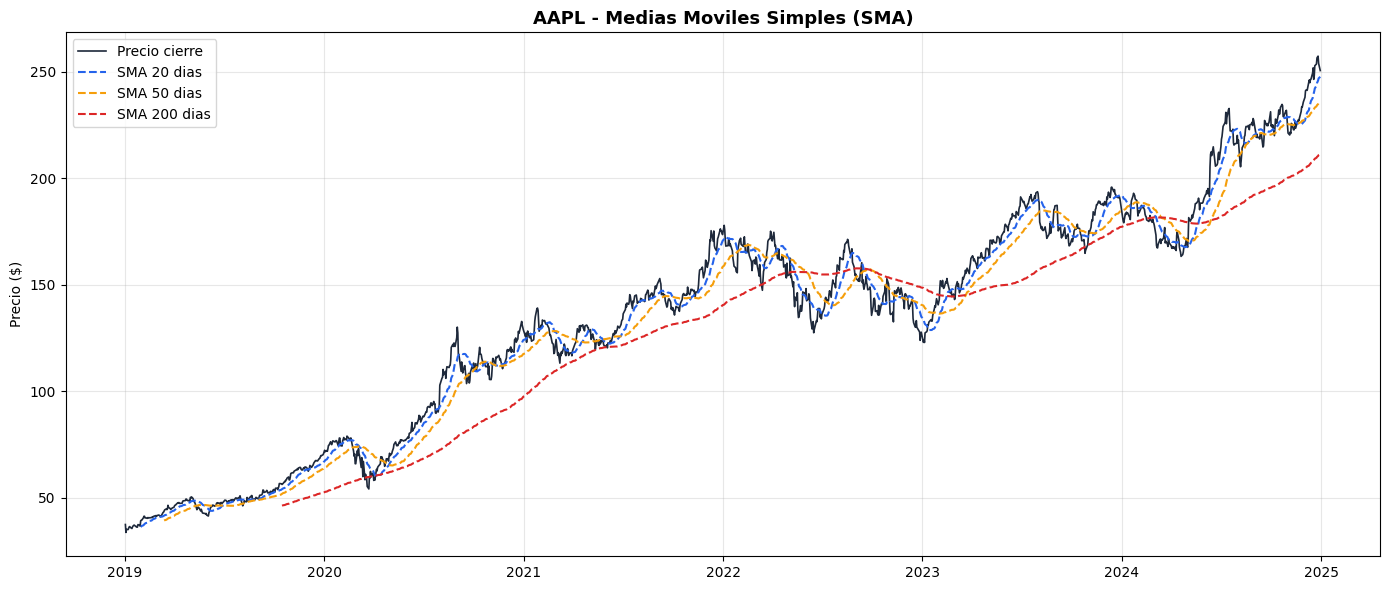

                 Close      SMA_20      SMA_50     SMA_200
Date                                                      
2024-12-23  253.649429  243.471442  233.786253  209.644961
2024-12-24  256.560822  244.729903  234.325889  210.072593
2024-12-26  257.375549  245.920294  234.831199  210.501923
2024-12-27  253.967377  246.946736  235.309438  210.924607
2024-12-30  250.598892  247.685516  235.712963  211.321192


In [2]:
# Media Movil Simple (SMA)
# Calculamos SMA de 20, 50 y 200 dias
df["SMA_20"]  = df["Close"].rolling(window=20).mean()
df["SMA_50"]  = df["Close"].rolling(window=50).mean()
df["SMA_200"] = df["Close"].rolling(window=200).mean()

# Visualizacion
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df.index, df["Close"],   label="Precio cierre", color="#1e293b", linewidth=1.2)
ax.plot(df.index, df["SMA_20"],  label="SMA 20 dias",   color="#2563eb", linewidth=1.5, linestyle="--")
ax.plot(df.index, df["SMA_50"],  label="SMA 50 dias",   color="#f59e0b", linewidth=1.5, linestyle="--")
ax.plot(df.index, df["SMA_200"], label="SMA 200 dias",  color="#dc2626", linewidth=1.5, linestyle="--")

ax.set_title(f"{ticker} - Medias Moviles Simples (SMA)", fontsize=13, fontweight="bold")
ax.set_ylabel("Precio ($)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/05_sma.png", dpi=150, bbox_inches="tight")
plt.show()

print(df[["Close", "SMA_20", "SMA_50", "SMA_200"]].tail(5))

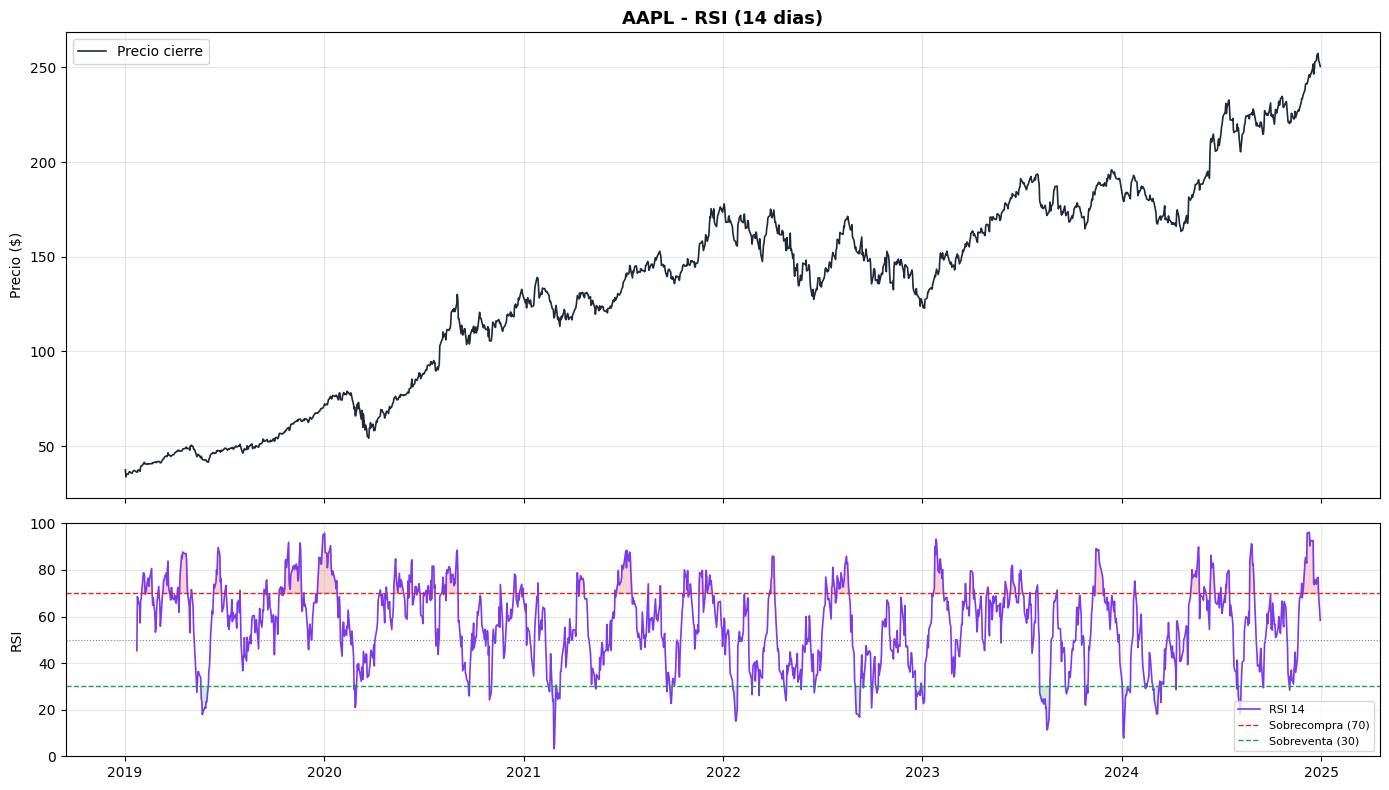

RSI actual (2024-12-30): 58.38


In [3]:
# RSI  Relative Strength Index
def calcular_rsi(serie, window=14):
    delta = serie.diff()
    ganancia = delta.clip(lower=0).rolling(window=window).mean()
    perdida = (-delta.clip(upper=0)).rolling(window=window).mean()
    rs = ganancia / perdida
    return 100 - (100 / (1 + rs))

df["RSI_14"] = calcular_rsi(df["Close"])

# Visualizacion
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, 
                                gridspec_kw={"height_ratios": [2, 1]})

# Panel superior - precio
ax1.plot(df.index, df["Close"], color="#1e293b", linewidth=1.2, label="Precio cierre")
ax1.set_ylabel("Precio ($)")
ax1.set_title(f"{ticker} - RSI (14 dias)", fontsize=13, fontweight="bold")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Panel inferior - RSI
ax2.plot(df.index, df["RSI_14"], color="#7c3aed", linewidth=1.2, label="RSI 14")
ax2.axhline(70, color="#dc2626", linewidth=1, linestyle="--", label="Sobrecompra (70)")
ax2.axhline(30, color="#16a34a", linewidth=1, linestyle="--", label="Sobreventa (30)")
ax2.axhline(50, color="gray",    linewidth=0.8, linestyle=":")
ax2.fill_between(df.index, df["RSI_14"], 70, 
                 where=(df["RSI_14"] >= 70), color="#dc2626", alpha=0.2)
ax2.fill_between(df.index, df["RSI_14"], 30, 
                 where=(df["RSI_14"] <= 30), color="#16a34a", alpha=0.2)
ax2.set_ylabel("RSI")
ax2.set_ylim(0, 100)
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/06_rsi.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"RSI actual ({df.index[-1].date()}): {df['RSI_14'].iloc[-1]:.2f}")

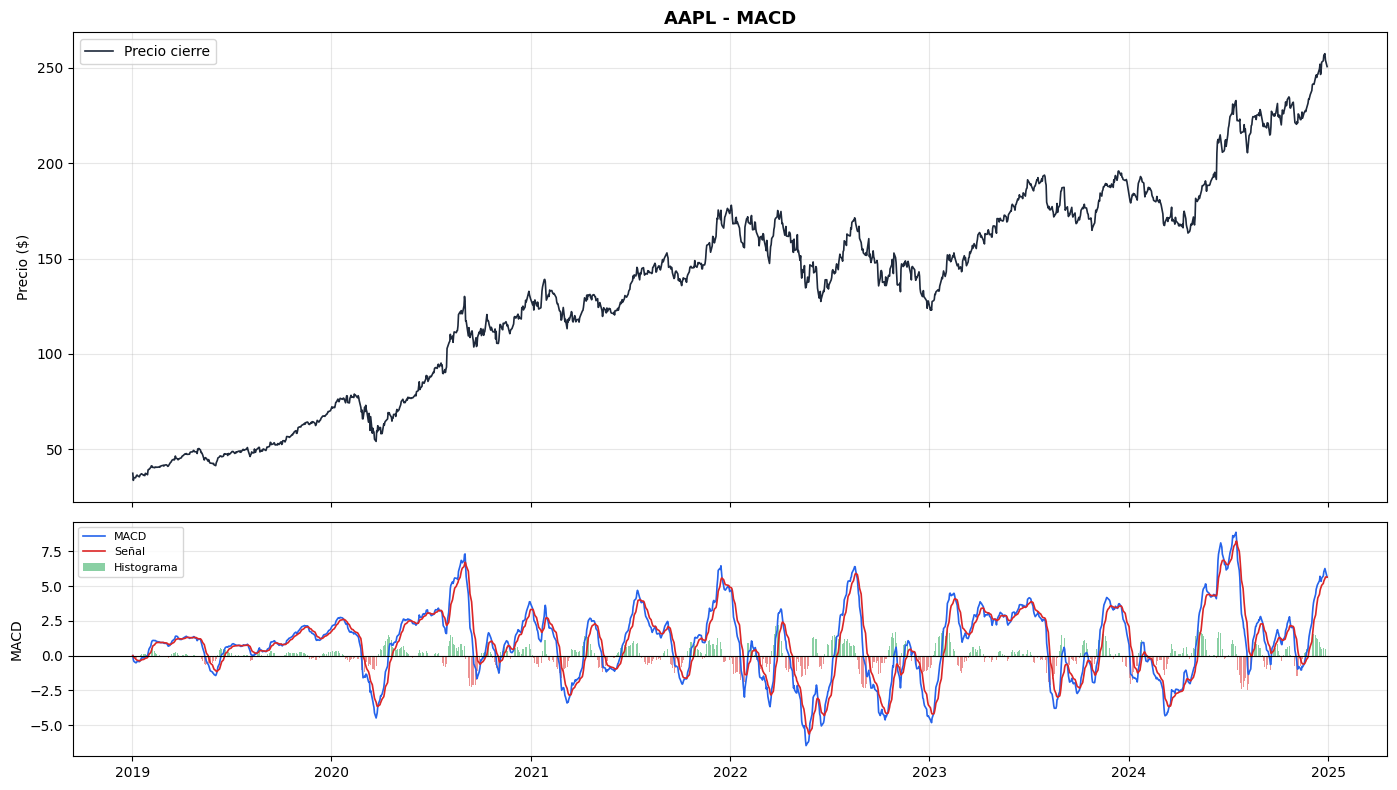

MACD actual       : 5.6398
Señal actual      : 5.6522
Histograma actual : -0.0124


In [4]:
# MACD  Moving Average Convergence Divergence
ema12 = df["Close"].ewm(span=12, adjust=False).mean()
ema26 = df["Close"].ewm(span=26, adjust=False).mean()

df["MACD"]        = ema12 - ema26
df["MACD_signal"] = df["MACD"].ewm(span=9, adjust=False).mean()
df["MACD_hist"]   = df["MACD"] - df["MACD_signal"]

# Visualizacion
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                gridspec_kw={"height_ratios": [2, 1]})

# Panel superior - precio
ax1.plot(df.index, df["Close"], color="#1e293b", linewidth=1.2, label="Precio cierre")
ax1.set_ylabel("Precio ($)")
ax1.set_title(f"{ticker} - MACD", fontsize=13, fontweight="bold")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Panel inferior - MACD
ax2.plot(df.index, df["MACD"],        color="#2563eb", linewidth=1.2, label="MACD")
ax2.plot(df.index, df["MACD_signal"], color="#dc2626", linewidth=1.2, label="Señal")
ax2.bar(df.index, df["MACD_hist"],
        color=["#16a34a" if v >= 0 else "#dc2626" for v in df["MACD_hist"]],
        alpha=0.5, label="Histograma", width=1)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_ylabel("MACD")
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/07_macd.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"MACD actual       : {df['MACD'].iloc[-1]:.4f}")
print(f"Señal actual      : {df['MACD_signal'].iloc[-1]:.4f}")
print(f"Histograma actual : {df['MACD_hist'].iloc[-1]:.4f}")

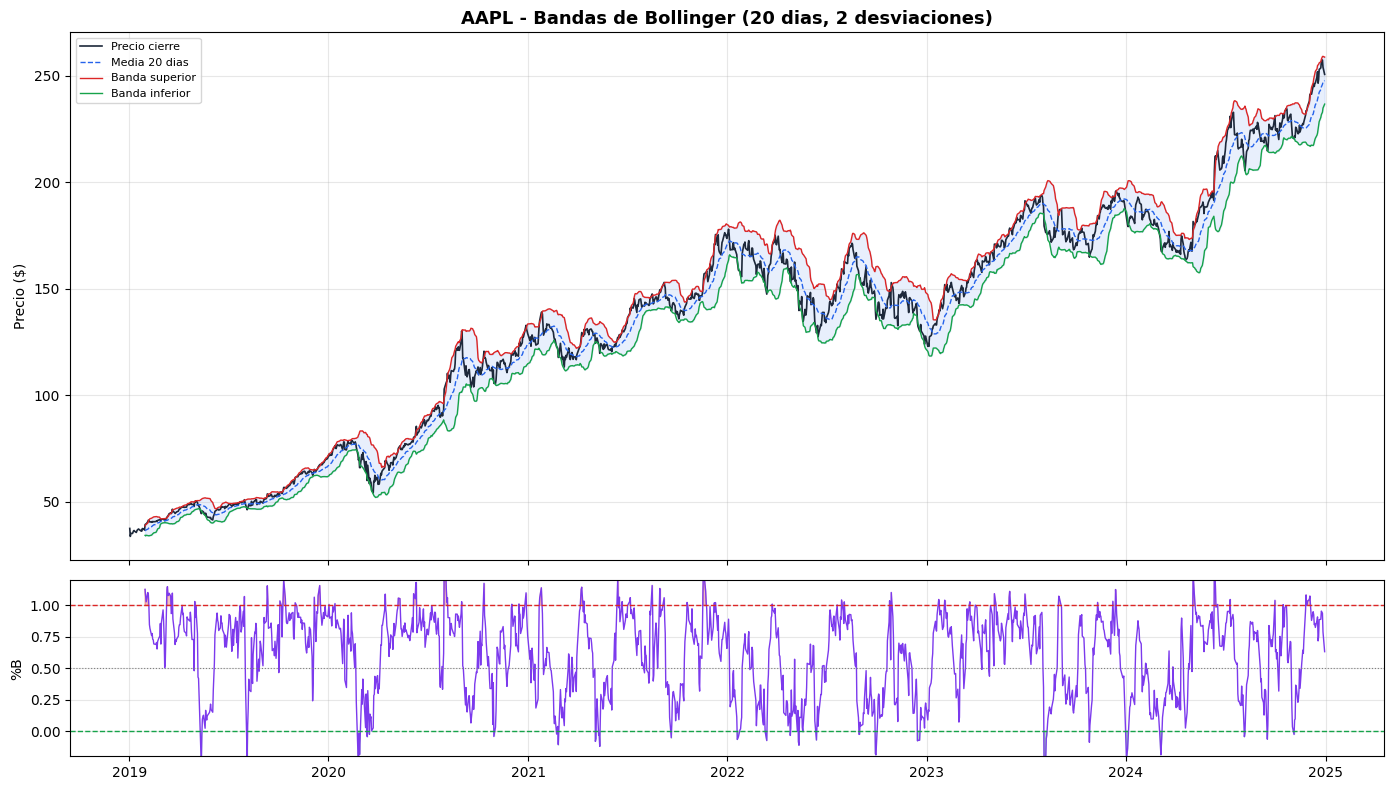

Banda superior : 258.72
Precio actual  : 250.60
Banda inferior : 236.65
BB percentil   : 0.63


In [5]:
# Bandas de Bollinger
window = 20
std = 2

df["BB_mid"]   = df["Close"].rolling(window=window).mean()
df["BB_upper"] = df["BB_mid"] + std * df["Close"].rolling(window=window).std()
df["BB_lower"] = df["BB_mid"] - std * df["Close"].rolling(window=window).std()
df["BB_pct"]   = (df["Close"] - df["BB_lower"]) / (df["BB_upper"] - df["BB_lower"])

# Visualizacion
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                gridspec_kw={"height_ratios": [3, 1]})

# Panel superior - precio con bandas
ax1.plot(df.index, df["Close"],    color="#1e293b", linewidth=1.2, label="Precio cierre")
ax1.plot(df.index, df["BB_mid"],   color="#2563eb", linewidth=1,   linestyle="--", label="Media 20 dias")
ax1.plot(df.index, df["BB_upper"], color="#dc2626", linewidth=1,   label="Banda superior")
ax1.plot(df.index, df["BB_lower"], color="#16a34a", linewidth=1,   label="Banda inferior")
ax1.fill_between(df.index, df["BB_upper"], df["BB_lower"], alpha=0.1, color="#2563eb")
ax1.set_ylabel("Precio ($)")
ax1.set_title(f"{ticker} - Bandas de Bollinger (20 dias, 2 desviaciones)", 
              fontsize=13, fontweight="bold")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

# Panel inferior - BB percentil
ax2.plot(df.index, df["BB_pct"], color="#7c3aed", linewidth=1)
ax2.axhline(1,   color="#dc2626", linewidth=1, linestyle="--")
ax2.axhline(0,   color="#16a34a", linewidth=1, linestyle="--")
ax2.axhline(0.5, color="gray",    linewidth=0.8, linestyle=":")
ax2.fill_between(df.index, df["BB_pct"], 1,
                 where=(df["BB_pct"] >= 1), color="#dc2626", alpha=0.3)
ax2.fill_between(df.index, df["BB_pct"], 0,
                 where=(df["BB_pct"] <= 0), color="#16a34a", alpha=0.3)
ax2.set_ylabel("%B")
ax2.set_ylim(-0.2, 1.2)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/08_bollinger.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Banda superior : {df['BB_upper'].iloc[-1]:.2f}")
print(f"Precio actual  : {df['Close'].iloc[-1]:.2f}")
print(f"Banda inferior : {df['BB_lower'].iloc[-1]:.2f}")
print(f"BB percentil   : {df['BB_pct'].iloc[-1]:.2f}")

METRICAS DE RIESGO - AAPL (2019-2024)
  Volatilidad anualizada : 30.85%
  Sharpe Ratio           : 1.0222
  VaR 95%  (diario)      : 2.95%
  CVaR 95% (diario)      : 4.37%
  Max Drawdown           : -31.43%


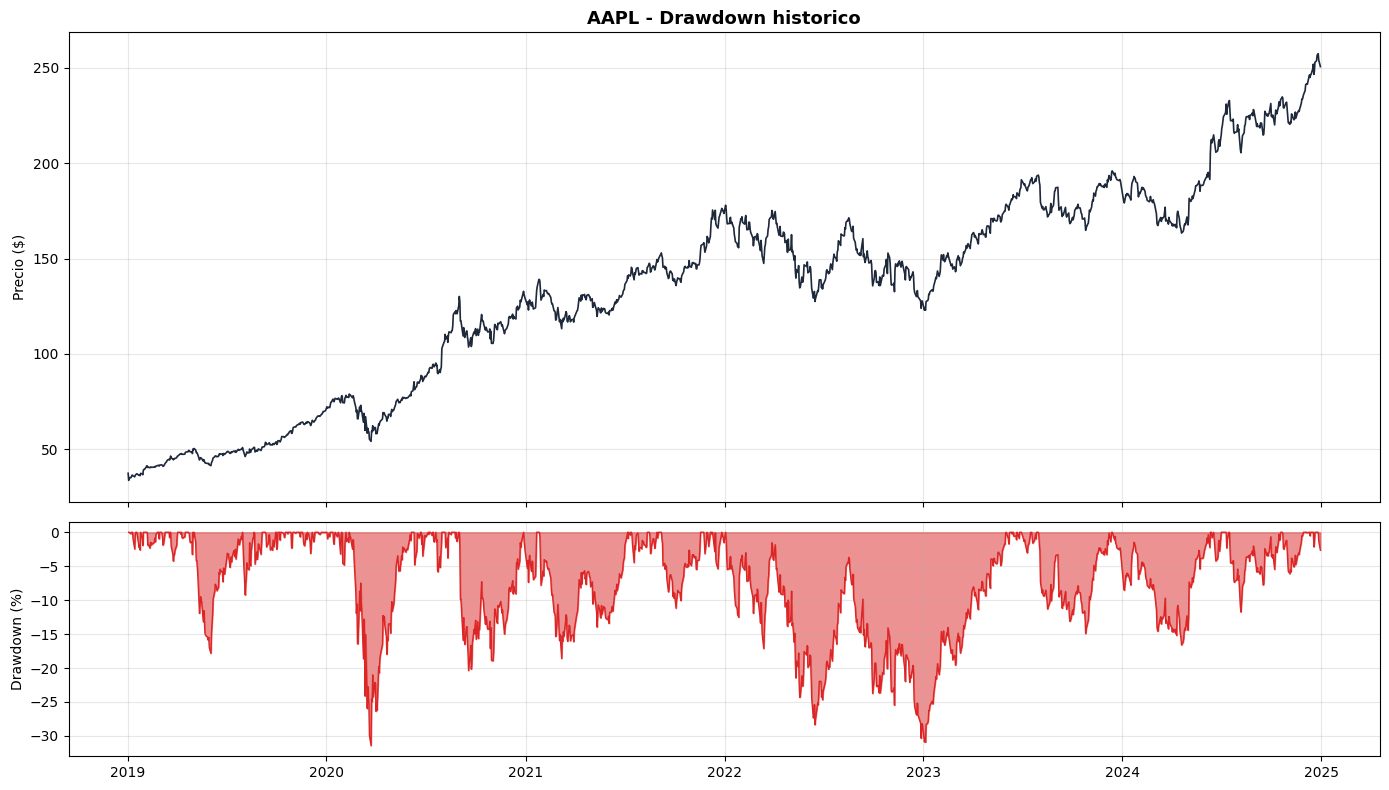

In [6]:
# Metricas de riesgo
retornos_aapl = df["Close"].pct_change().dropna()

# Sharpe Ratio
rf_diaria      = 0.05 / 252  # Tasa libre de riesgo diaria (5% anual)
exceso         = retornos_aapl - rf_diaria
sharpe         = (exceso.mean() / exceso.std()) * np.sqrt(252)

# Volatilidad anualizada
volatilidad    = retornos_aapl.std() * np.sqrt(252)

# Value at Risk (VaR) al 95%
var_95         = -np.percentile(retornos_aapl, 5)

# CVaR - perdida media mas alla del VaR
cvar_95        = -retornos_aapl[retornos_aapl <= -var_95].mean()

# Max Drawdown
acumulado      = (1 + retornos_aapl).cumprod()
maximo_rolling = acumulado.cummax()
drawdown       = (acumulado - maximo_rolling) / maximo_rolling
max_drawdown   = drawdown.min()

print("METRICAS DE RIESGO - AAPL (2019-2024)")
print("="*45)
print(f"  Volatilidad anualizada : {volatilidad*100:.2f}%")
print(f"  Sharpe Ratio           : {sharpe:.4f}")
print(f"  VaR 95%  (diario)      : {var_95*100:.2f}%")
print(f"  CVaR 95% (diario)      : {cvar_95*100:.2f}%")
print(f"  Max Drawdown           : {max_drawdown*100:.2f}%")

# Visualizacion del drawdown
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                gridspec_kw={"height_ratios": [2, 1]})

ax1.plot(df.index, df["Close"], color="#1e293b", linewidth=1.2)
ax1.set_ylabel("Precio ($)")
ax1.set_title(f"{ticker} - Drawdown historico", fontsize=13, fontweight="bold")
ax1.grid(True, alpha=0.3)

ax2.fill_between(drawdown.index, drawdown.values * 100, 0, 
                 color="#dc2626", alpha=0.5)
ax2.plot(drawdown.index, drawdown.values * 100, color="#dc2626", linewidth=1)
ax2.set_ylabel("Drawdown (%)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/09_drawdown.png", dpi=150, bbox_inches="tight")
plt.show()